# Stage 6 — Resolution study

Crack segmentation and measurement project. Explanations: see the study guide.

In [1]:
# Cell 1 — Install, import and settings
%pip install -q segmentation-models-pytorch

from pathlib import Path
import json
import os

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.morphology import skeletonize
import torch
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

DATA_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SCALES = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]     # <1 = camera further away, >1 = closer
N_IMAGES = {"DeepCrack": 100, "CFD": 40}       # sources whose labels follow the crack edges
ERROR_TARGET = 0.25                            # acceptable median width error: 25%
LIMIT_MM = 0.3
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

found = [Path(r) / f for r, _, fs in os.walk(DATA_ROOT, followlinks=True) for f in fs if f == "thresholds.json"]
THRESHOLD = float(next(iter(json.load(open(found[0])).values()))) if found else 0.35
checkpoint = sorted(Path(r) / f for r, _, fs in os.walk(DATA_ROOT, followlinks=True)
                    for f in fs if f.startswith("best_") and f.endswith(".pth"))[0]
model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
model = model.to(DEVICE).eval()
torch.set_num_threads(4)
print("device:", DEVICE, "| model:", checkpoint.name, "| threshold:", THRESHOLD)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 2.8 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.
device: cuda | model: best_resnet34_seed0.pth | threshold: 0.35


In [2]:
# Cell 2 — Measurement functions (from Stage 5)
def skeleton_length(skel):
    s = skel.astype(np.uint8)
    straight = (s[:, :-1] & s[:, 1:]).sum() + (s[:-1, :] & s[1:, :]).sum()
    diagonal = (s[:-1, :-1] & s[1:, 1:]).sum() + (s[:-1, 1:] & s[1:, :-1]).sum()
    return float(straight + np.sqrt(2) * diagonal)

def median_width(mask, min_px=30):
    mask = mask.astype(bool)
    if mask.sum() < min_px:
        return np.nan
    dist = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
    return float(np.median(2 * dist[skeletonize(mask)] - 1))

def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)

In [3]:
# Cell 3 — Choose test images with clear cracks
folders = {p.name: p for p in DATA_ROOT.rglob("*") if p.is_dir() and p.name in {"Images", "Images-2", "Masks"}}
rng = np.random.default_rng(0)
picked = []
for source, n in N_IMAGES.items():
    paths = sorted(p for f in ("Images", "Images-2") for p in folders[f].glob(f"{source}_*.png"))
    paths = [p for p in paths if load_mask(folders["Masks"] / p.name).sum() >= 300]
    for p in rng.choice(paths, size=min(n, len(paths)), replace=False):
        picked.append({"source": source, "image": str(p), "mask": str(folders["Masks"] / p.name)})
picked = pd.DataFrame(picked)
print(picked["source"].value_counts())

source
DeepCrack    100
CFD           40
Name: count, dtype: int64


In [4]:
# Cell 4 — Predict an image at a different resolution
@torch.no_grad()
def predict_at_scale(image, scale):
    h, w = image.shape[:2]
    size = (round(w * scale), round(h * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC     # shrink by averaging, enlarge smoothly
    img = cv2.resize(image, size, interpolation=interp)
    H, W = img.shape[:2]
    ph, pw = (-H) % 32, (-W) % 32                                 # pad up to a multiple of 32
    img = cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_REFLECT_101)
    x = (img.astype(np.float32) / 255 - MEAN) / STD
    x = torch.from_numpy(x.transpose(2, 0, 1))[None].to(DEVICE)
    with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
        prob = torch.sigmoid(model(x).float())[0, 0, :H, :W]
    return (prob >= THRESHOLD).cpu().numpy()

In [5]:
# Cell 5 — Measure every image at every scale
rows = []
for _, r in tqdm(picked.iterrows(), total=len(picked)):
    image = np.array(Image.open(r["image"]).convert("RGB"))
    label_w = median_width(load_mask(r["mask"]))
    for s in SCALES:
        pred_w_scaled = median_width(predict_at_scale(image, s))
        rows.append({"source": r["source"], "image": Path(r["image"]).name, "scale": s,
                     "label_w": label_w,                         # original pixels
                     "true_w_px": label_w * s,                   # crack width in the pixels the model saw
                     "pred_w_px": pred_w_scaled,
                     "rel_error": (pred_w_scaled / s - label_w) / label_w})
res = pd.DataFrame(rows).dropna()
print(res.groupby("scale")[["true_w_px", "pred_w_px", "rel_error"]].median().round(2))

  0%|          | 0/140 [00:00<?, ?it/s]

       true_w_px  pred_w_px  rel_error
scale                                 
0.50        1.74       7.00       2.33
0.75        2.60       7.25       1.33
1.00        3.47       7.94       1.00
1.50        5.21      10.66       0.62
2.00        6.94      12.42       0.50
3.00       10.42      15.00       0.24


             n  median   q25   q75  bin_mid
width_bin                                  
(0, 2]     140    3.67  2.65  4.87      1.0
(2, 3]     124    1.65  1.33  2.11      2.5
(3, 4]      56    1.32  1.01  1.56      3.5
(4, 5]      64    0.98  0.61  1.04      4.5
(5, 6]      88    0.78  0.63  1.00      5.5
(6, 8]      57    0.57  0.42  0.64      7.0
(8, 10]     77    0.35  0.22  0.49      9.0
(10, 12]    39    0.26  0.18  0.42     11.0
(12, 15]    43    0.16  0.07  0.29     13.5
(15, 20]    47    0.09 -0.09  0.23     17.5
(20, 30]    46    0.04 -0.14  0.15     25.0
(30, 60]    27   -0.06 -0.32  0.01     45.0

Median width error stays within 25% once a crack is wider than 12 px


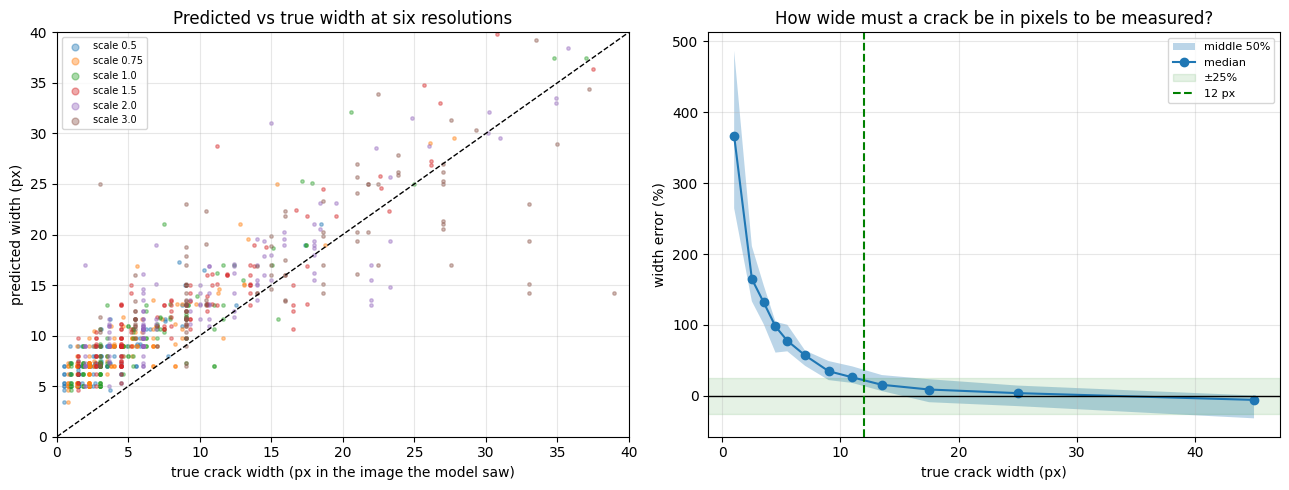

In [6]:
# Cell 6 — Width error against crack width in pixels
bins = [0, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, 60]
res["width_bin"] = pd.cut(res["true_w_px"], bins)
curve = res.groupby("width_bin", observed=True)["rel_error"].agg(
    n="size", median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
curve["bin_mid"] = [(b.left + b.right) / 2 for b in curve.index]
print(curve.round(2).to_string())

# smallest width from which every well-populated bin (n >= 20) stays within the target
N_MIN = np.nan
for b in reversed(curve.index):
    if curve.loc[b, "n"] < 20:
        continue
    if abs(curve.loc[b, "median"]) <= ERROR_TARGET:
        N_MIN = float(b.left)
    else:
        break
if np.isnan(N_MIN):
    print(f"\nNo tested width reached a median error within {ERROR_TARGET:.0%}")
else:
    print(f"\nMedian width error stays within {ERROR_TARGET:.0%} once a crack is wider than {N_MIN:g} px")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for s, g in res.groupby("scale"):
    axes[0].scatter(g["true_w_px"], g["pred_w_px"], s=6, alpha=0.4, label=f"scale {s}")
axes[0].plot([0, 40], [0, 40], "k--", lw=1)
axes[0].set_xlim(0, 40)
axes[0].set_ylim(0, 40)
axes[0].set_xlabel("true crack width (px in the image the model saw)")
axes[0].set_ylabel("predicted width (px)")
axes[0].set_title("Predicted vs true width at six resolutions")
axes[0].legend(fontsize=7, markerscale=2)
axes[1].fill_between(curve["bin_mid"], 100 * curve["q25"], 100 * curve["q75"], alpha=0.3, label="middle 50%")
axes[1].plot(curve["bin_mid"], 100 * curve["median"], "o-", label="median")
axes[1].axhspan(-100 * ERROR_TARGET, 100 * ERROR_TARGET, color="green", alpha=0.1, label=f"±{ERROR_TARGET:.0%}")
axes[1].axhline(0, color="k", lw=1)
if not np.isnan(N_MIN):
    axes[1].axvline(N_MIN, color="green", ls="--", label=f"{N_MIN:g} px")
axes[1].set_xlabel("true crack width (px)")
axes[1].set_ylabel("width error (%)")
axes[1].set_title("How wide must a crack be in pixels to be measured?")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "resolution_curve.png", dpi=120)
plt.show()

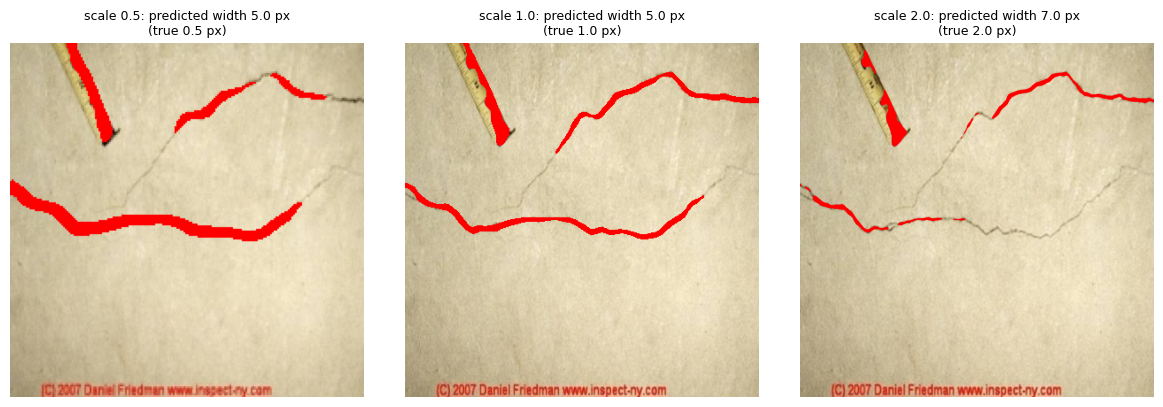

In [7]:
# Cell 7 — One crack at three resolutions
r = picked.iloc[0]
image = np.array(Image.open(r["image"]).convert("RGB"))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, s in zip(axes, [0.5, 1.0, 2.0]):
    pred = predict_at_scale(image, s)
    shown = cv2.resize(image, pred.shape[::-1], interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC).copy()
    shown[pred] = [255, 0, 0]
    ax.imshow(shown)
    ax.set_title(f"scale {s}: predicted width {median_width(pred):.1f} px\n"
                 f"(true {median_width(load_mask(r['mask'])) * s:.1f} px)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
# Cell 8 — From pixels to a camera distance
def max_distance_mm(n_px, image_px=4032, hfov_deg=70.0, crack_mm=LIMIT_MM):
    """Furthest distance at which a crack of crack_mm covers n_px pixels."""
    mm_per_px_needed = crack_mm / n_px
    return mm_per_px_needed * image_px / (2 * np.tan(np.radians(hfov_deg) / 2))

cameras = [("Phone main camera, 12 MP", 4032, 70), ("Phone main camera, 4000 px", 4000, 70),
           ("Phone 2x telephoto, 12 MP", 4032, 38), ("Phone 3x telephoto, 12 MP", 4032, 25)]
rows = []
for name, px, fov in cameras:
    d = max_distance_mm(N_MIN, px, fov)
    scene = 2 * d * np.tan(np.radians(fov) / 2)
    rows.append({"camera": name, "max distance (cm)": d / 10, "wall width per photo (cm)": scene / 10,
                 "mm per pixel": scene / px})
camera_table = pd.DataFrame(rows).round(2)
print(f"To measure a {LIMIT_MM} mm crack it must span at least {N_MIN:g} px:\n")
print(camera_table.to_string(index=False))

To measure a 0.3 mm crack it must span at least 12 px:

                    camera  max distance (cm)  wall width per photo (cm)  mm per pixel
  Phone main camera, 12 MP               7.20                      10.08          0.02
Phone main camera, 4000 px               7.14                      10.00          0.02
 Phone 2x telephoto, 12 MP              14.64                      10.08          0.02
 Phone 3x telephoto, 12 MP              22.73                      10.08          0.02


In [9]:
# Cell 9 — Save
res.drop(columns="width_bin").to_csv(OUT_DIR / "resolution_results.csv", index=False)
curve.drop(columns="bin_mid").to_csv(OUT_DIR / "resolution_curve.csv")
camera_table.to_csv(OUT_DIR / "camera_distances.csv", index=False)
json.dump({"min_width_px": N_MIN, "error_target": ERROR_TARGET}, open(OUT_DIR / "resolution_rule.json", "w"))
print("saved")

saved
